# Valor presente do zero

**Quanto o dinheiro do futuro vale hoje: juros compostos, juros sobre juros, descontar, a taxa que muda tudo, a convenção brasileira de dias úteis (com o preço oficial do Tesouro Prefixado reproduzido ao centavo), a curva do DI, o parcelado "sem juros" e o preço de uma ação como dinheiro futuro descontado**

Gabriel Pires · [@gabrielp.pires](https://instagram.com/gabrielp.pires) · [gabrielppires.com](https://gabrielppires.com) · série *Finanças Quantitativas do Zero* · outubro de 2026 · Temporada 2, parte 2

---

A 5 % ao ano, **\$100 que você recebe daqui a 10 anos valem só \$61,39 hoje**. O vídeo mostra por quê em 10 linhas de Python. Este notebook reproduz cada número dele e vai além:

| Seção | O que você leva |
|---|---|
| 0 | O código da tela (`vp.py`), linha por linha |
| 1 | Juros compostos, eq. (1): \$105 em um ano, \$162,89 em dez |
| 2 | De onde vêm os \$12,89 de juros sobre juros: o binômio, eq. (2) |
| 3 | Rodar ao contrário: descontar e conferir, eq. (3) |
| 4 | A taxa muda tudo: 2 %, 5 %, 10 % e a Selic de 13,75 %; a sensibilidade, eq. (4) |
| 5 | Quanto tempo para dobrar: a regra de 72, eq. (5) |
| 6 | Mesma taxa, quatro respostas: as convenções de juros |
| 7 | No Brasil: dias úteis e o preço oficial do Tesouro Prefixado, eq. (6) |
| 8 | Mesa de operações: a curva do DI como fator de desconto, eq. (7) |
| 9 | Investidor: à vista com desconto ou 10× "sem juros"? |
| 10 | Na teoria, o preço de tudo: perpetuidade e Gordon, eq. (8) |
| 11 | O que o valor presente não vê + exercícios |

**Dados:** as seções 0 a 6 usam os números de exemplo do vídeo (em dólar, como no original). A seção 7 usa as taxas e os preços **reais** do Tesouro Prefixado publicados pelo Tesouro Transparente (`dados_td/tesouro_prefixado_2024_2026.csv`, de 02/01/2024 a 09/10/2026); a seção 8, os ajustes do DI futuro de 09/10/2026.

> O vídeo é inspirado na Parte 6 de *Quant Finance from Scratch*, de [@quantfinancetogo](https://instagram.com/quantfinancetogo). Só educação. Não é recomendação de investimento.

## 0. O código da tela

São as 10 linhas que aparecem digitadas no vídeo. Tudo o que vem depois explica, verifica e estende estas linhas.

In [1]:
import numpy as np
taxa = 0.05                         # 5 % ao ano
anos = np.arange(11)                # ano 0 a 10
dinheiro = 100 * (1 + taxa) ** anos
print(dinheiro[[1, 10]].round(2)) # 105 e 162.89
futuro = 100                        # pago no ano 10
hoje = futuro / (1 + taxa) ** 10
print(round(hoje, 2))              # 61.39 hoje
for r in [0.02, 0.05, 0.10]:
    print(r, round(100 / (1 + r) ** 10, 2))

[105.   162.89]
61.39
0.02 82.03
0.05 61.39
0.1 38.55


### Bibliotecas e estilo dos gráficos

In [2]:
import datetime as dt_
import math
import pandas as pd
import matplotlib.pyplot as plt

NAVY, BLUE, LIGHT, RED, GREEN, GREY, GOLD = "#1B2A4A", "#1E56B8", "#5B8DEF", "#B42318", "#1B7A4A", "#6B7590", "#B7791F"
plt.rcParams.update({
    "figure.figsize": (9, 4.6), "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.25, "axes.edgecolor": GREY, "axes.labelcolor": NAVY,
    "xtick.color": GREY, "ytick.color": GREY, "axes.titleweight": "bold", "axes.titlecolor": NAVY,
    "text.parse_math": False,          # "R$ 1 ... R$ 2" é dinheiro, não fórmula
})
br = lambda v, d=2: f"{v:,.{d}f}".replace(",", "X").replace(".", ",").replace("X", ".").replace("-", "−")   # 1.234,56
usd = lambda v, d=2: "$" + br(v, d)
brl = lambda v, d=2: ("−" if v < 0 else "") + "R$ " + br(abs(v), d)
fmt = dict(decimal=",", thousands=".")

## 1. Juros compostos — eq. (1)

Coloque \$100 no banco a 5 % ao ano. No primeiro ano, os juros são \$5. No segundo, são 5 % de \$105, ou seja, **\$5,25**: os \$0,25 a mais são juros sobre os juros do primeiro ano. Todo ano o saldo é multiplicado por 1,05:

$$
VF = VP\,(1+r)^{n} \tag{1}
$$

com $VP$ o valor de hoje, $r$ a taxa por período e $n$ o número de períodos. Com **juros simples** (5 % sempre sobre os \$100 iniciais), o saldo cresceria em linha reta: $VP\,(1 + n\,r)$.

ano,compostos (1),simples,juros sobre juros
0,"100,00","100,00","0,00"
1,"105,00","105,00","0,00"
2,"110,25","110,00","0,25"
3,"115,76","115,00","0,76"
4,"121,55","120,00","1,55"
5,"127,63","125,00","2,63"
6,"134,01","130,00","4,01"
7,"140,71","135,00","5,71"
8,"147,75","140,00","7,75"
9,"155,13","145,00","10,13"


ano 2: juros de $5,25 (5 % de $105), dos quais $0,25 são juros sobre juros
ano 10: $162,89 compostos × $150,00 simples -> $12,89 de juros sobre juros
$1 hoje vira $1,63 em 10 anos


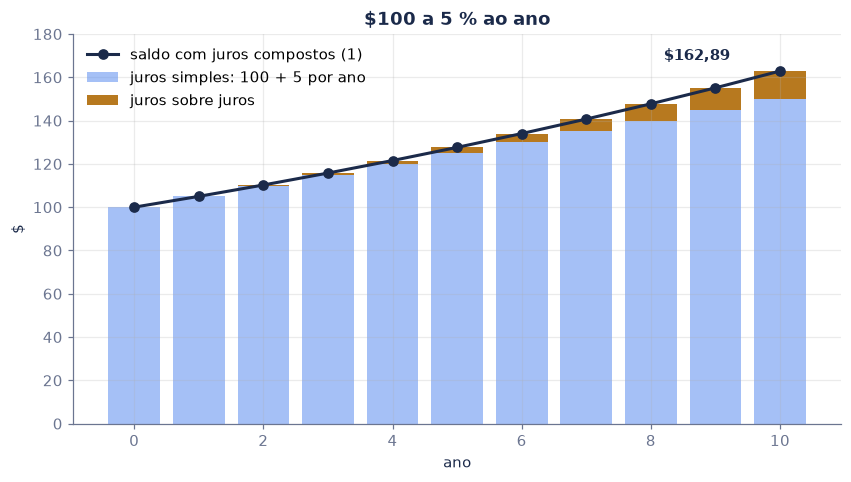

In [3]:
simples = 100 * (1 + taxa * anos)
tab = pd.DataFrame({"ano": anos, "compostos (1)": dinheiro, "simples": simples, "juros sobre juros": dinheiro - simples})
display(tab.style.format({"compostos (1)": "{:,.2f}", "simples": "{:,.2f}", "juros sobre juros": "{:,.2f}"}, **fmt).hide(axis="index"))
print(f"ano 2: juros de {usd(0.05 * 105)} (5 % de $105), dos quais {usd(0.05 * 105 - 5)} são juros sobre juros")
print(f"ano 10: {usd(dinheiro[10])} compostos × {usd(simples[10])} simples -> {usd(dinheiro[10] - simples[10])} de juros sobre juros")
print(f"$1 hoje vira {usd(1.05 ** 10)} em 10 anos")
assert [round(float(dinheiro[1]), 2), round(float(dinheiro[10]), 2)] == [105.0, 162.89]
assert round(0.05 * 105, 2) == 5.25 and round(float(dinheiro[10] - simples[10]), 2) == 12.89 and round(1.05 ** 10, 2) == 1.63

fig, ax = plt.subplots()
ax.bar(anos, simples, color=LIGHT, alpha=0.55, label="juros simples: 100 + 5 por ano")
ax.bar(anos, dinheiro - simples, bottom=simples, color=GOLD, label="juros sobre juros")
ax.plot(anos, dinheiro, "o-", color=NAVY, lw=2, label="saldo com juros compostos (1)")
ax.annotate(f"{usd(dinheiro[10])}", (10, dinheiro[10]), (8.2, 168), color=NAVY, weight="bold")
ax.set(title="$100 a 5 % ao ano", xlabel="ano", ylabel="$", ylim=(0, 180)); ax.legend(frameon=False, loc="upper left"); plt.show()

## 2. De onde vêm os \$12,89 — eq. (2)

Abra $(1+r)^n$ pelo binômio de Newton:

$$
(1+r)^n = \sum_{k=0}^{n}\binom{n}{k} r^k = \underbrace{1 + n\,r}_{\text{juros simples}} + \underbrace{\binom{n}{2}r^2 + \binom{n}{3}r^3 + \cdots}_{\text{juros sobre juros}} \tag{2}
$$

Cada termo tem leitura: $\binom{n}{2}r^2$ são os juros que os juros de **um** ano rendem em **cada um** dos anos seguintes (45 pares de anos em 10); $\binom{n}{3}r^3$ são os juros dos juros dos juros; e assim por diante. Com $r$ pequeno, os termos encolhem rápido, e por isso juros simples são uma boa aproximação para prazos curtos e uma péssima para prazos longos.

termos de 100·C(10,k)·0,05^k: 100,00 + 50,00 + 11,25 + 1,50 + 0,13 + 0,01 + ...
soma = $162,89  |  juros sobre juros (k ≥ 2) = $12,89 = 11,25 + 1,50 + 0,14


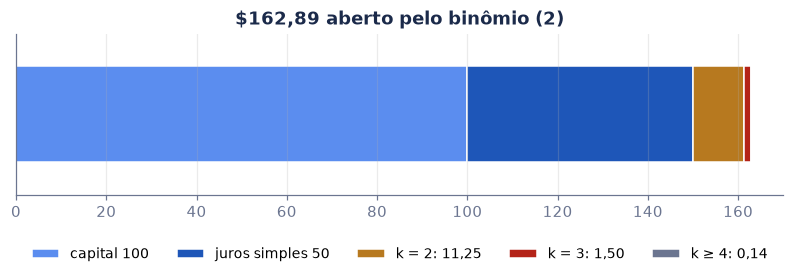

In [4]:
termos = np.array([100 * math.comb(10, k) * taxa ** k for k in range(11)])
print("termos de 100·C(10,k)·0,05^k:", " + ".join(br(v) for v in termos[:6]), "+ ...")
print(f"soma = {usd(termos.sum())}  |  juros sobre juros (k ≥ 2) = {usd(termos[2:].sum())} = {br(termos[2])} + {br(termos[3])} + {br(termos[4:].sum())}")
assert np.isclose(termos.sum(), dinheiro[10]) and round(termos[2], 2) == 11.25 and round(termos[3], 2) == 1.5

fig, ax = plt.subplots(figsize=(9, 1.9))
esq, cores, nomes = 0, [LIGHT, BLUE, GOLD, RED, GREY], ["capital 100", "juros simples 50", "k = 2: 11,25", "k = 3: 1,50", "k ≥ 4: 0,14"]
for v, c, nome in zip([termos[0], termos[1], termos[2], termos[3], termos[4:].sum()], cores, nomes):
    ax.barh(0, v, left=esq, height=0.6, color=c, edgecolor="white", label=nome); esq += v
ax.set(yticks=[], ylim=(-0.5, 0.5), xlim=(0, 170), title="$162,89 aberto pelo binômio (2)")
ax.legend(frameon=False, ncol=5, fontsize=9, loc="upper center", bbox_to_anchor=(0.5, -0.25)); plt.show()

## 3. Rodar ao contrário: descontar — eq. (3)

Se \$1 hoje vira \$1,63 em 10 anos, então **\$1 hoje vale mais do que \$1 daqui a 10 anos**: ele já pode render juros. Esse é o **valor do dinheiro no tempo**. Para saber quanto vale hoje um dinheiro que só chega no futuro, isole $VP$ na eq. (1):

$$
VP = \frac{VF}{(1+r)^{n}} \tag{3}
$$

É dividir por 1,05 uma vez para cada ano. Isso se chama **descontar**, e $1/(1+r)^n$ é o **fator de desconto**. A conferência do vídeo é a eq. (1) aplicada ao resultado: \$61,39 no banco a 5 % viram exatamente \$100.

ano 10: $100,00
ano  9: $95,24   <- dividir por 1,05 de novo
ano  8: $90,70   <- dividir por 1,05 de novo
ano  1: $64,46   <- dividir por 1,05 de novo
ano  0: $61,39

fator de desconto 1/1,05^10 = 0,613913
conferência: $61,39 × 1,05^10 = $100,00


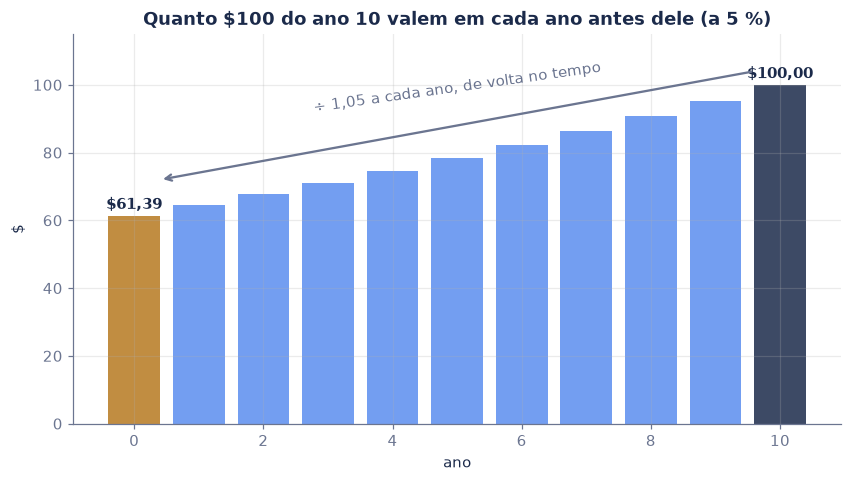

In [5]:
volta = [100 / 1.05 ** (10 - n) for n in range(11)]      # o $100 do ano 10 trazido ano a ano
for n in (10, 9, 8, 1, 0):
    print(f"ano {n:2d}: {usd(volta[n])}" + ("   <- dividir por 1,05 de novo" if 0 < n < 10 else ""))
print(f"\nfator de desconto 1/1,05^10 = {br(1 / 1.05 ** 10, 6)}")
print(f"conferência: {usd(hoje)} × 1,05^10 = {usd(hoje * 1.05 ** 10)}")
assert round(hoje, 2) == 61.39 and round(hoje * 1.05 ** 10, 2) == 100.0

fig, ax = plt.subplots()
ax.bar(anos, volta, color=[GOLD] + [LIGHT] * 9 + [NAVY], alpha=0.85)
for n in (0, 10):
    ax.text(n, volta[n] + 2, usd(volta[n]), ha="center", color=NAVY, weight="bold")
ax.annotate("", xy=(0.4, 72), xytext=(9.6, 104), arrowprops=dict(arrowstyle="->", color=GREY, lw=1.5))
ax.text(5, 92, "÷ 1,05 a cada ano, de volta no tempo", ha="center", color=GREY, rotation=8)
ax.set(title="Quanto $100 do ano 10 valem em cada ano antes dele (a 5 %)", xlabel="ano", ylabel="$", ylim=(0, 115)); plt.show()

## 4. A taxa muda tudo — eq. (4)

Os mesmos \$100 daqui a 10 anos valem \$82,03 hoje a 2 % e só \$38,55 a 10 %. Com a **Selic de 13,75 %** (o patamar desde setembro de 2026), valem **R\$ 27,57**: a taxa come mais de 70 % do valor.

Quanto o valor presente muda quando a taxa muda? Derive a eq. (3):

$$
\frac{dVP}{dr} = -\frac{n}{1+r}\,VP \tag{4}
$$

A 5 %, isso dá $-\tfrac{10}{1{,}05} \times 61{,}39 \approx -585$ por unidade de taxa, ou **−\$5,85 por ponto percentual**. Note o $n$ na frente: **quanto mais longe o dinheiro, mais ele treme com a taxa**. Esse $n/(1+r)$ é a semente da *duration*, tema do episódio 4 desta temporada.

A curva não é uma reta: cair 1 ponto (para 4 %) **ganha** \$6,17, subir 1 ponto (para 6 %) **perde** só \$5,55. Essa curvatura é a *convexidade* (episódio 5).

           2 %: $100,00 em 10 anos valem    $82,03 hoje  (fator 0,8203)
           5 %: $100,00 em 10 anos valem    $61,39 hoje  (fator 0,6139)
          10 %: $100,00 em 10 anos valem    $38,55 hoje  (fator 0,3855)
 Selic 13,75 %: R$ 100,00 em 10 anos valem  R$ 27,57 hoje  (fator 0,2757)

eq. (4) a 5 %: −584,7 por unidade de taxa = −5,85 por ponto
exato: 4 % -> $67,56 (+6,17);  6 % -> $55,84 (−5,55)


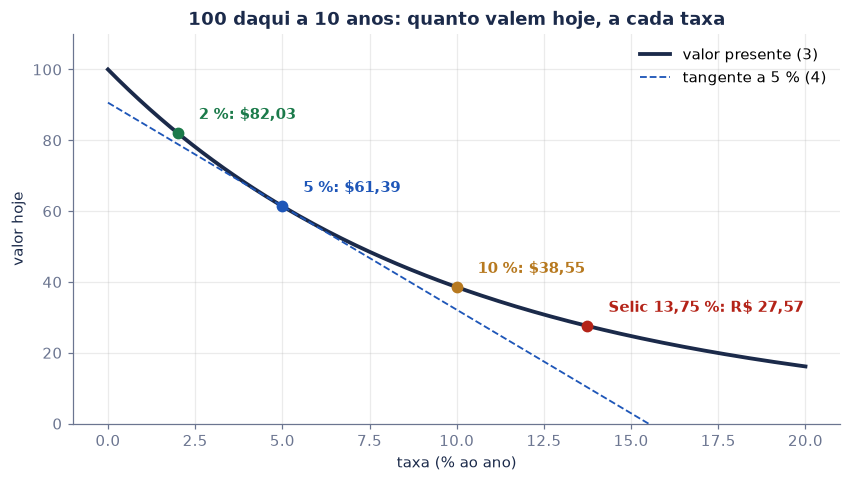

In [6]:
vp = lambda r, n=10, vf=100: vf / (1 + r) ** n
taxas = {"2 %": 0.02, "5 %": 0.05, "10 %": 0.10, "Selic 13,75 %": 0.1375}
moeda = lambda nome, v: brl(v) if "Selic" in nome else usd(v)     # o exemplo da Selic é em reais
for nome, r in taxas.items():
    print(f"{nome:>14}: {moeda(nome, 100)} em 10 anos valem {moeda(nome, vp(r)):>9} hoje  (fator {br(1 / (1 + r) ** 10, 4)})")
deriv = -10 / 1.05 * vp(0.05)
print(f"\neq. (4) a 5 %: {br(deriv, 1)} por unidade de taxa = {br(deriv / 100)} por ponto")
print(f"exato: 4 % -> {usd(vp(0.04))} ({'+' + br(vp(0.04) - vp(0.05))});  6 % -> {usd(vp(0.06))} ({br(vp(0.06) - vp(0.05))})")
assert [round(vp(r), 2) for r in (0.02, 0.05, 0.10, 0.1375)] == [82.03, 61.39, 38.55, 27.57]
assert round(deriv / 100, 2) == -5.85 and round(vp(0.04) - vp(0.05), 2) == 6.17 and round(vp(0.06) - vp(0.05), 2) == -5.55

rr = np.linspace(0, 0.20, 201)
fig, ax = plt.subplots()
ax.plot(rr * 100, vp(rr), color=NAVY, lw=2.5, label="valor presente (3)")
ax.plot(rr * 100, vp(0.05) + deriv * (rr - 0.05), color=BLUE, lw=1.2, ls="--", label="tangente a 5 % (4)")
for (nome, r), c in zip(taxas.items(), [GREEN, BLUE, GOLD, RED]):
    ax.scatter([r * 100], [vp(r)], color=c, zorder=3, s=45); ax.annotate(f"{nome}: {moeda(nome, vp(r))}", (r * 100, vp(r)), (r * 100 + 0.6, vp(r) + 4), color=c, weight="bold")
ax.set(title="100 daqui a 10 anos: quanto valem hoje, a cada taxa", xlabel="taxa (% ao ano)", ylabel="valor hoje", ylim=(0, 110)); ax.legend(frameon=False); plt.show()

## 5. Quanto tempo para dobrar — eq. (5)

Rodando a eq. (1) para $VF = 2\,VP$ e isolando $n$:

$$
n_{\times 2} = \frac{\ln 2}{\ln(1+r)} \approx \frac{72}{100\,r} \tag{5}
$$

A aproximação vem de $\ln(1+r) \approx r$ e $\ln 2 \approx 0{,}693$; o 72 no lugar do 69,3 compensa o erro de $\ln(1+r) < r$ nas taxas usuais (e tem muitos divisores). A 5 %, o dinheiro dobra em 14,2 anos; a 13,75 %, em 5,4.

In [7]:
linhas = [{"taxa": r, "exato (5)": math.log(2) / math.log(1 + r), "regra de 72": 72 / (100 * r), "regra de 69,3": 69.3 / (100 * r)} for r in (0.02, 0.05, 0.10, 0.1375, 0.25)]
display(pd.DataFrame(linhas).style.format({"taxa": "{:.2%}", "exato (5)": "{:.2f}", "regra de 72": "{:.2f}", "regra de 69,3": "{:.2f}"}, **fmt).hide(axis="index"))
assert round(math.log(2) / math.log(1.05), 1) == 14.2 and round(math.log(2) / math.log(1.1375), 1) == 5.4

taxa,exato (5),regra de 72,"regra de 69,3"
"2,00%","35,00","36,00","34,65"
"5,00%","14,21","14,40","13,86"
"10,00%","7,27","7,20","6,93"
"13,75%","5,38","5,24","5,04"
"25,00%","3,11","2,88","2,77"


## 6. Mesma taxa, quatro respostas: as convenções

"5 % ao ano" não diz tudo: falta dizer **como** os juros se acumulam. Os mesmos \$100 em 10 anos, a "5 % ao ano":

- **anual composta** (a do vídeo e, com dias úteis, a do Brasil): $100/1{,}05^{10}$;
- **mensal** (5 %/12 ao mês, comum em crédito ao consumidor e nos EUA): $100/(1 + 0{,}05/12)^{120}$;
- **contínua** (a dos livros de derivativos): $100\,e^{-0{,}05 \times 10}$;
- **simples** (só para prazos curtos): $100/(1 + 0{,}05 \times 10)$.

Quanto mais vezes os juros são capitalizados, mais eles rendem e menor é o valor presente; no limite, $(1 + r/m)^{m} \to e^{r}$. Na mesa, confundir convenção é erro de verdade: uma taxa só é comparável com outra na mesma base.

In [8]:
conv = {"anual composta": 100 / 1.05 ** 10, "mensal (5 %/12)": 100 / (1 + 0.05 / 12) ** 120, "contínua": 100 * math.exp(-0.5), "simples": 100 / (1 + 0.05 * 10)}
for nome, v in conv.items():
    print(f"{nome:>16}: {usd(v)}")
print(f"\na taxa anual composta equivalente à mensal de 5 %/12: {br(100 * ((1 + 0.05 / 12) ** 12 - 1), 3)} % ao ano")
assert [round(v, 2) for v in conv.values()] == [61.39, 60.72, 60.65, 66.67]

  anual composta: $61,39
 mensal (5 %/12): $60,72
        contínua: $60,65
         simples: $66,67

a taxa anual composta equivalente à mensal de 5 %/12: 5,116 % ao ano


## 7. No Brasil: dias úteis e o preço oficial do Tesouro Prefixado — eq. (6)

O Tesouro Prefixado (LTN) é a eq. (3) com um único fluxo: ele paga **R\$ 1.000** no vencimento e nada antes. A convenção brasileira conta o prazo em **dias úteis** sobre um ano de **252**:

$$
PU = \frac{1.000}{(1 + \text{taxa})^{du/252}} \tag{6}
$$

Dá para conferir a eq. (6) contra o preço que o Tesouro publica. Três detalhes de mesa fazem o centavo bater:

1. **Calendário:** os dias úteis seguem o calendário nacional da ANBIMA (feriados fixos, carnaval, sexta-feira santa, Corpus Christi e, desde 2024, 20 de novembro).
2. **Liquidação:** o preço vale para o dia útil **seguinte** ao da negociação, e o Tesouro não liquida em 24 e 31 de dezembro (pula para o próximo dia útil). Os dias úteis contam a partir da liquidação.
3. **Truncamento:** o PU é **truncado** (não arredondado) em duas casas.

In [9]:
def pascoa(y):
    a, b, c = y % 19, y // 100, y % 100
    d_, e, f_ = b // 4, b % 4, (b + 8) // 25
    g = (b - f_ + 1) // 3
    h = (19 * a + b - d_ - g + 15) % 30
    i, k = c // 4, c % 4
    l = (32 + 2 * e + 2 * i - h - k) % 7
    m = (a + 11 * h + 22 * l) // 451
    return dt_.date(y, (h + l - 7 * m + 114) // 31, (h + l - 7 * m + 114) % 31 + 1)

FER = []
for y in range(2024, 2041):
    p = pascoa(y)
    FER += [dt_.date(y, 1, 1), p - dt_.timedelta(48), p - dt_.timedelta(47), p - dt_.timedelta(2), dt_.date(y, 4, 21), dt_.date(y, 5, 1),
            p + dt_.timedelta(60), dt_.date(y, 9, 7), dt_.date(y, 10, 12), dt_.date(y, 11, 2), dt_.date(y, 11, 15), dt_.date(y, 11, 20), dt_.date(y, 12, 25)]
FER = np.array(FER, dtype="datetime64[D]")

UM_DIA = np.timedelta64(1, "D")

def liquidacao(d):
    d = np.datetime64(d, "D") + UM_DIA
    while not np.is_busday(d, holidays=FER) or str(d)[5:] in ("12-24", "12-31"):
        d += UM_DIA
    return d

def pu_ltn(taxa, data, venc):
    liq, venc = liquidacao(data), np.datetime64(venc, "D")
    if liq > venc:                            # vence em 01/01 e é cotado em 30/12: liquida em 31/12 mesmo
        liq = np.busday_offset(np.datetime64(data, "D"), 1, roll="forward", holidays=FER)
    du = np.busday_count(liq, venc, holidays=FER)
    return du, math.floor(1000 / (1 + taxa) ** (du / 252) * 100) / 100     # (6), truncado em 2 casas

ltn = pd.read_csv("dados_td/tesouro_prefixado_2024_2026.csv", sep=";", decimal=",", dayfirst=True, parse_dates=["Data Vencimento", "Data Base"])
print(f"{len(ltn)} preços de compra do Tesouro Prefixado, de {ltn['Data Base'].min():%d/%m/%Y} a {ltn['Data Base'].max():%d/%m/%Y}")

3757 preços de compra do Tesouro Prefixado, de 02/01/2024 a 09/10/2026


In [10]:
dia = ltn[ltn["Data Base"] == "2026-10-09"].sort_values("Data Vencimento")
calc = [pu_ltn(t / 100, d, v) for t, d, v in zip(dia["Taxa Compra Manha"], dia["Data Base"], dia["Data Vencimento"])]
hoje_td = pd.DataFrame({
    "título": [f"Prefixado {v:%Y}" for v in dia["Data Vencimento"]], "vencimento": dia["Data Vencimento"].dt.strftime("%d/%m/%Y"),
    "taxa": dia["Taxa Compra Manha"].values / 100, "du": [c[0] for c in calc], "PU pela eq. (6)": [c[1] for c in calc], "PU do Tesouro": dia["PU Compra Manha"].values,
})
display(hoje_td.style.format({"taxa": "{:.2%}", "PU pela eq. (6)": "{:,.2f}", "PU do Tesouro": "{:,.2f}"}, **fmt).hide(axis="index").set_caption("09/10/2026 (sexta): liquidação na terça 13/10, porque segunda 12/10 é feriado"))
assert (hoje_td["PU pela eq. (6)"] == hoje_td["PU do Tesouro"]).all()

calc_all = [pu_ltn(t / 100, d, v) for t, d, v in zip(ltn["Taxa Compra Manha"], ltn["Data Base"], ltn["Data Vencimento"])]
ltn["du"] = [c[0] for c in calc_all]
ltn["erro"] = np.round([c[1] for c in calc_all] - ltn["PU Compra Manha"].values, 2)
excecao = [liquidacao(d) > np.datetime64(v, "D") for d, v in zip(ltn["Data Base"], ltn["Data Vencimento"])]
print("a exceção de 31/12 (vence em 01/01, cotado em 30/12):")
print(ltn.loc[excecao, ["Data Base", "Data Vencimento", "Taxa Compra Manha", "du", "PU Compra Manha"]].to_string(index=False))
assert sum(excecao) == 2
print(f"\ntodos os {len(ltn)} preços de 2024 a 2026: {br(100 * (ltn['erro'] == 0).mean(), 1)} % iguais ao centavo; maior diferença R$ {br(ltn['erro'].abs().max())}")
assert (ltn["erro"] == 0).all()

título,vencimento,taxa,du,PU pela eq. (6),PU do Tesouro
Prefixado 2027,01/01/2027,"13,28%",55,"973,15","973,15"
Prefixado 2028,01/01/2028,"12,49%",306,"866,82","866,82"
Prefixado 2029,01/01/2029,"12,30%",554,"774,89","774,89"
Prefixado 2031,01/01/2031,"12,45%",1.055,"611,86","611,86"
Prefixado 2032,01/01/2032,"12,54%",1.307,"541,87","541,87"


a exceção de 31/12 (vence em 01/01, cotado em 30/12):
 Data Base Data Vencimento  Taxa Compra Manha  du  PU Compra Manha
2024-12-30      2025-01-01              12.20   1           999.54
2025-12-30      2026-01-01              14.94   1           999.44

todos os 3757 preços de 2024 a 2026: 100,0 % iguais ao centavo; maior diferença R$ 0,00


**Leitura.** A eq. (6), as regras de calendário e um truncamento reproduzem **todos** os 3.757 preços de compra do Tesouro Prefixado desde 2024, ao centavo. A única exceção de calendário aparece duas vezes: o título que vence em 1º de janeiro, cotado em 30 de dezembro, liquida no próprio 31/12 (com 1 dia útil até o vencimento), porque pular o 31/12 faria ele vencer antes de ser pago. O vídeo usa anos inteiros; o Tesouro usa dias úteis. A conta é a mesma.

Um efeito curioso da convenção: na sexta 09/10/2026, como a segunda era feriado, o comprador só pagou na terça. Os dias úteis contam a partir dela, e por isso o preço daquele dia já desconta um prazo menor.

## 8. Mesa de operações: a curva do DI como fator de desconto — eq. (7)

Na mesa, ninguém desconta tudo a uma taxa só. Cada data tem a sua taxa, lida na **curva do DI futuro** da B3: o contrato DI1 paga 100.000 pontos no vencimento, e seu preço é a eq. (6) com 100.000 no lugar de 1.000. Dividindo o PU por 100.000, sai o **fator de desconto** daquela data, que vale para qualquer fluxo prefixado. O valor presente de um conjunto de fluxos é a soma da eq. (3) data a data:

$$
VP = \sum_{j} CF_j\,\delta_j, \qquad \delta_j = \frac{1}{(1 + y_j)^{du_j/252}} \tag{7}
$$

Exemplo: uma empresa tem **R\$ 1 milhão a receber no início de 2027, de 2028 e de 2029** (um contrato de fornecimento, por exemplo). Quanto vale hoje? Os ajustes do DI de 09/10/2026 são os mesmos do episódio da curva de juros. No DI, os dias úteis contam a partir do próprio dia.

In [11]:
du_ = lambda a, b: int(np.busday_count(np.datetime64(a, "D"), np.datetime64(b, "D"), holidays=FER))
def vencimento(y):
    v = np.datetime64(f"{y}-01-01")
    while not np.is_busday(v, holidays=FER):
        v += UM_DIA
    return v

HOJE = np.datetime64("2026-10-09")
ANOS = [2027, 2028, 2029, 2031, 2032, 2033, 2034, 2035]
DI = np.array([13.439, 12.520, 12.220, 12.245, 12.310, 12.350, 12.375, 12.365]) / 100
DU = np.array([du_(HOJE, vencimento(y)) for y in ANOS])
delta = 1 / (1 + DI) ** (DU / 252)
curva = pd.DataFrame({"contrato": [f"DI1F{str(y)[2:]}" for y in ANOS], "du": DU, "taxa": DI, "PU (pontos)": 1e5 * delta, "fator δ": delta})
display(curva.style.format({"taxa": "{:.3%}", "PU (pontos)": "{:,.2f}", "fator δ": "{:.6f}"}, **fmt).hide(axis="index"))

cf = np.array([1e6, 1e6, 1e6])
vp_curva = (cf * delta[:3]).sum()                                  # (7)
vp_selic = (cf / 1.1375 ** (DU[:3] / 252)).sum()
print(f"R$ 3 mi em 3 parcelas: VP pela curva do DI = {brl(vp_curva)}  |  tudo a 13,75 % = {brl(vp_selic)}  |  diferença {brl(vp_curva - vp_selic)}")
assert list(DU[:3]) == [56, 307, 555]

contrato,du,taxa,PU (pontos),fator δ
DI1F27,56,"13,439%","97.236,78","0,972368"
DI1F28,307,"12,520%","86.614,22","0,866142"
DI1F29,555,"12,220%","77.575,79","0,775758"
DI1F31,1.056,"12,245%","61.627,76","0,616278"
DI1F32,1.308,"12,310%","54.739,94","0,547399"
DI1F33,1.560,"12,350%","48.632,72","0,486327"
DI1F34,1.811,"12,375%","43.237,62","0,432376"
DI1F35,2.059,"12,365%","38.575,55","0,385755"


R$ 3 mi em 3 parcelas: VP pela curva do DI = R$ 2.614.267,89  |  tudo a 13,75 % = R$ 2.579.485,32  |  diferença R$ 34.782,58


**Leitura.** A curva de 09/10/2026 cai depois do primeiro vértice: o mercado espera cortes da Selic. Por isso descontar tudo à Selic de hoje **subestima** os fluxos longos, e a diferença do exemplo acima é dinheiro de verdade numa negociação de recebíveis. Por que a curva tem esse formato, e o que ela diz sobre o Copom, é o assunto do episódio 6 desta temporada.

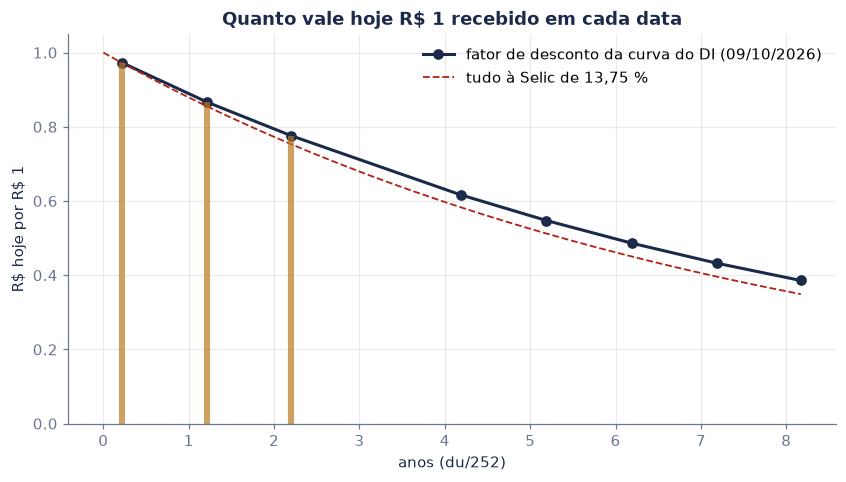

In [12]:
fig, ax = plt.subplots()
ax.plot(DU / 252, delta, "o-", color=NAVY, lw=2, label="fator de desconto da curva do DI (09/10/2026)")
xs = np.linspace(0, DU[-1] / 252, 100)
ax.plot(xs, 1 / 1.1375 ** xs, color=RED, lw=1.2, ls="--", label="tudo à Selic de 13,75 %")
for j in range(3):
    ax.vlines(DU[j] / 252, 0, delta[j], color=GOLD, lw=4, alpha=0.7)
ax.set(title="Quanto vale hoje R$ 1 recebido em cada data", xlabel="anos (du/252)", ylabel="R$ hoje por R$ 1", ylim=(0, 1.05)); ax.legend(frameon=False); plt.show()

## 9. Para o investidor: à vista com desconto ou 10× "sem juros"?

Uma compra de **R\$ 1.000** pode ser paga à vista com desconto ou em **10 parcelas de R\$ 100**, a primeira daqui a um mês. "Sem juros" para a loja não quer dizer sem custo para você: enquanto as parcelas não vencem, o dinheiro pode render. O valor presente das parcelas é a eq. (7) com uma taxa só, que tem fórmula fechada (a soma de uma progressão geométrica):

$$
VP_{\text{parcelas}} = \sum_{j=1}^{10} \frac{P}{(1+i)^{j}} = P\,\frac{1 - (1+i)^{-10}}{i}
$$

com $P$ = R\$ 100 e $i$ a taxa **mensal** do seu dinheiro. Se ele fica no CDI (13,65 % ao ano em 09/10/2026), $i = 1{,}1365^{1/12} - 1$. Se o desconto à vista for **maior** que $1 - VP_{\text{parcelas}}/1.000$, pague à vista; se for menor, parcele e deixe o dinheiro rendendo.

                  100 % do CDI (bruto): i = 1,072 % ao mês -> parcelas valem R$ 943,48 hoje -> desconto de empate 5,7 %
 80 % do CDI (≈ líquido de IR de 20 %): i = 0,867 % ao mês -> parcelas valem R$ 953,90 hoje -> desconto de empate 4,6 %
                poupança (~7 % ao ano): i = 0,565 % ao mês -> parcelas valem R$ 969,59 hoje -> desconto de empate 3,0 %


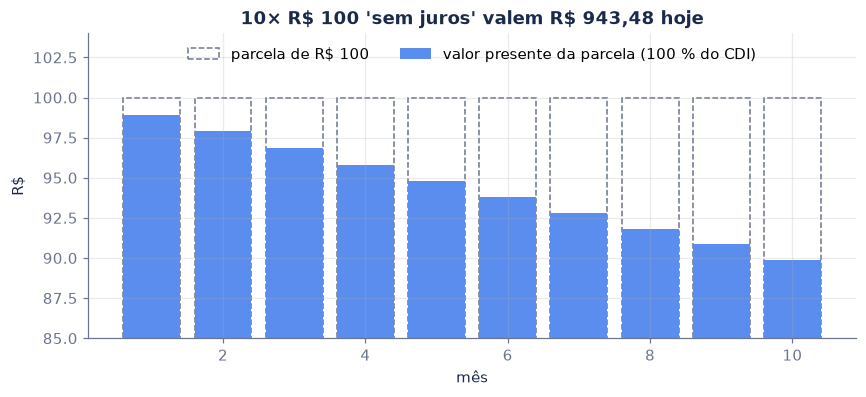

In [13]:
anuidade = lambda P, i, n=10: P * (1 - (1 + i) ** -n) / i
casos = {"100 % do CDI (bruto)": 0.1365, "80 % do CDI (≈ líquido de IR de 20 %)": 0.1365 * 0.8, "poupança (~7 % ao ano)": 0.07}
for nome, a in casos.items():
    i = (1 + a) ** (1 / 12) - 1
    v = anuidade(100, i)
    print(f"{nome:>38}: i = {br(100 * i, 3)} % ao mês -> parcelas valem {brl(v)} hoje -> desconto de empate {br(100 * (1 - v / 1000), 1)} %")
i_cdi = 1.1365 ** (1 / 12) - 1
v_cdi = anuidade(100, i_cdi)
assert round(v_cdi, 2) == 943.48 and round(100 * (1 - v_cdi / 1000), 1) == 5.7

fig, ax = plt.subplots(figsize=(9, 3.6))
js = np.arange(1, 11)
ax.bar(js, np.full(10, 100), color="none", edgecolor=GREY, ls="--", label="parcela de R$ 100")
ax.bar(js, 100 / (1 + i_cdi) ** js, color=LIGHT, label="valor presente da parcela (100 % do CDI)")
ax.set(title=f"10× R$ 100 'sem juros' valem {brl(v_cdi)} hoje", xlabel="mês", ylabel="R$", ylim=(85, 104)); ax.legend(frameon=False, loc="upper center", ncol=2); plt.show()

**Leitura.** Com o dinheiro no CDI, as 10 parcelas valem cerca de R\$ 943 hoje: um desconto à vista acima de ~5,7 % ganha do parcelado. Depois do imposto de renda, a régua cai para ~4,6 %; na poupança, para ~3,0 %. A mesma conta vale para qualquer "sem juros": o preço à vista **é** o valor presente que a loja aceita.

## 10. Na teoria, o preço de tudo — eq. (8)

O fecho do vídeo: *o preço de um investimento é o dinheiro que ele vai te pagar, descontado de volta para hoje*. Para um título, os fluxos estão no contrato. Para uma **ação**, são os dividendos, que não têm data para acabar. Se o fluxo é $C$ por ano para sempre, a soma da eq. (7) é uma progressão geométrica infinita; se ele cresce a uma taxa $g < r$ (o **modelo de Gordon**):

$$
VP = \sum_{t=1}^{\infty}\frac{C}{(1+r)^t} = \frac{C}{r}
\qquad\qquad
VP = \sum_{t=1}^{\infty}\frac{C\,(1+g)^{t-1}}{(1+r)^t} = \frac{C}{r-g} \tag{8}
$$

Duas consequências:

1. **A maior parte do preço de uma ação vem de longe.** Com $r$ = 10 % e $g$ = 3 %, os dividendos dos primeiros 10 anos explicam só 48 % do preço; os outros 52 % vêm depois do ano 10.
2. **Por isso ações de crescimento tremem tanto com a taxa.** O denominador é $r - g$: de 7 % para 8 % (um ponto a mais na taxa), o preço cai 12,5 %. É a eq. (4) com um $n$ enorme.

(Ninguém sabe $g$ nem $r$ ao certo; o modelo mostra para onde o preço anda quando eles mudam, não qual é o preço certo.)

dividendo de R$ 5 crescendo 3 % ao ano: a 10 % vale R$ 71,43; a 11 %, R$ 62,50 (−12,5 %)
parte do preço que vem dos primeiros 10 anos: 48,2 %


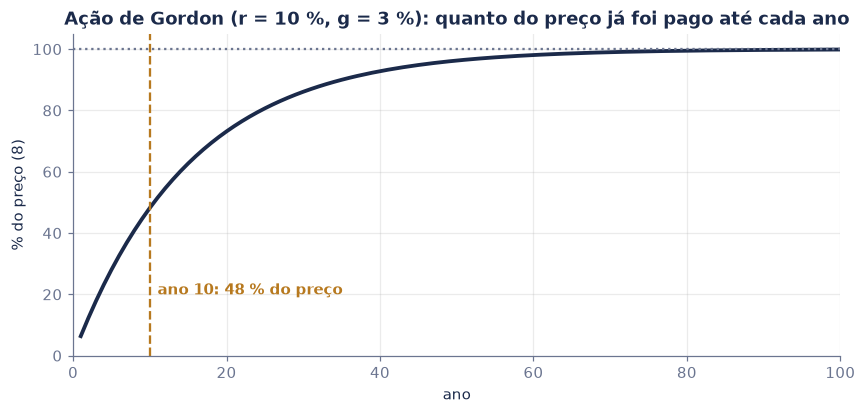

In [14]:
C, g = 5.0, 0.03
gordon = lambda r: C / (r - g)
t = np.arange(1, 201)
vp_t = C * (1 + g) ** (t - 1) / (1.10) ** t
frac10 = vp_t[:10].sum() / gordon(0.10)
print(f"dividendo de R$ 5 crescendo 3 % ao ano: a 10 % vale {brl(gordon(0.10))}; a 11 %, {brl(gordon(0.11))} ({br(100 * (gordon(0.11) / gordon(0.10) - 1), 1)} %)")
print(f"parte do preço que vem dos primeiros 10 anos: {br(100 * frac10, 1)} %")
assert round(gordon(0.10), 2) == 71.43 and round(100 * (gordon(0.11) / gordon(0.10) - 1), 1) == -12.5 and round(100 * frac10) == 48

fig, ax = plt.subplots(figsize=(9, 3.8))
ax.plot(t, np.cumsum(vp_t) / gordon(0.10) * 100, color=NAVY, lw=2.5)
ax.axvline(10, color=GOLD, ls="--"); ax.text(11, 20, f"ano 10: {br(100 * frac10, 0)} % do preço", color=GOLD, weight="bold")
ax.axhline(100, color=GREY, ls=":")
ax.set(title="Ação de Gordon (r = 10 %, g = 3 %): quanto do preço já foi pago até cada ano", xlabel="ano", ylabel="% do preço (8)", xlim=(0, 100), ylim=(0, 105)); plt.show()

## 11. O que o valor presente não vê

1. **A taxa não é uma só.** O vídeo desconta tudo a 5 %; o mercado tem uma taxa para cada prazo (seção 8). → *A curva de juros*, episódio 6.
2. **A taxa muda depois que você compra.** O valor presente de hoje vira outro amanhã; o título "seguro" oscila. → *O título "seguro" que oscila* (episódio 3), *Duration* (4) e *Convexidade* (5).
3. **O fluxo pode não chegar.** A eq. (3) supõe que os \$100 vêm com certeza. Com risco de calote, o fluxo esperado é menor e a taxa pede um prêmio. → Temporada 8, *Crédito do zero*.
4. **Dinheiro nominal não é poder de compra.** \$100 daqui a 10 anos compram menos que \$100 hoje. Descontar com a taxa nominal dá reais de hoje; para poder de compra, use juro real. → *Juro real e inflação implícita*, episódio 11.
5. **Imposto e custos.** O Tesouro Prefixado paga IR regressivo sobre o ganho e taxa de custódia da B3; o valor presente líquido é menor que o da eq. (6).

### Para praticar (respostas na célula seguinte)

1. Quanto valem hoje R\$ 1.000 recebidos daqui a 3 anos, a 12 % ao ano? E a 8 %?
2. Pela regra de 72, em quantos anos um dinheiro dobra a 9 % ao ano? Quanto dá a conta exata?
3. Um Tesouro Prefixado vence daqui a 504 dias úteis e a taxa é 12,5 %. Qual o PU (sem truncar)?
4. Uma perpetuidade paga R\$ 10 por ano, sem crescimento. Quanto vale a 8 %? E a 10 %?

In [15]:
print("1)", f"1.000/1,12^3 = {brl(1000 / 1.12 ** 3)};  1.000/1,08^3 = {brl(1000 / 1.08 ** 3)}")
print("2)", f"72/9 = 8 anos; exato ln 2/ln 1,09 = {br(math.log(2) / math.log(1.09))} anos")
print("3)", f"1.000/1,125^(504/252) = 1.000/1,125^2 = {brl(1000 / 1.125 ** 2)}")
print("4)", f"10/0,08 = {brl(10 / 0.08)};  10/0,10 = {brl(10 / 0.10)}")

1) 1.000/1,12^3 = R$ 711,78;  1.000/1,08^3 = R$ 793,83
2) 72/9 = 8 anos; exato ln 2/ln 1,09 = 8,04 anos
3) 1.000/1,125^(504/252) = 1.000/1,125^2 = R$ 790,12
4) 10/0,08 = R$ 125,00;  10/0,10 = R$ 100,00


---

### Resumo de fórmulas

| | Fórmula | Neste notebook |
|---|---|---|
| (1) Juros compostos | $VF = VP\,(1+r)^n$ | \$100 → \$105 → \$162,89 |
| (2) Binômio | $(1+r)^n = 1 + nr + \binom{n}{2}r^2 + \cdots$ | 100 + 50 + 11,25 + 1,50 + 0,14 |
| (3) Valor presente | $VP = VF/(1+r)^n$ | \$61,39 a 5 %; \$82,03 a 2 %; \$38,55 a 10 %; R\$ 27,57 à Selic |
| (4) Sensibilidade | $dVP/dr = -\frac{n}{1+r}\,VP$ | −\$5,85 por ponto, a 5 % |
| (5) Tempo para dobrar | $\ln 2/\ln(1+r) \approx 72/(100r)$ | 14,2 anos a 5 % |
| (6) Convenção brasileira | $PU = 1.000/(1+\text{taxa})^{du/252}$ | preço oficial do Tesouro Prefixado ao centavo |
| (7) Vários fluxos | $VP = \sum_j CF_j\,\delta_j$ | curva do DI; 10× sem juros |
| (8) Perpetuidade e Gordon | $C/r$ e $C/(r-g)$ | 48 % do preço nos 10 primeiros anos |

*Gabriel Pires · gabrielppires.com · Só educação, não é recomendação de investimento. Números de exemplo nas seções 0–6; dados reais do Tesouro Transparente e do DI de 09/10/2026 nas seções 7–8.*